# Exercise: Graphical EDA — Swiss EV Charging Stations

In this exercise you will apply the graphical EDA methods from the concept notebook to the **Swiss public EV charging stations** dataset.

## Dataset columns (recap)
| Column | Type | Description |
|---|---|---|
| `power_kw` | numeric | Charging power in kW |
| `amperage` | numeric | Current in A |
| `voltage` | numeric | Voltage in V |
| `power_type` | categorical | AC_3_PHASE / DC / AC_1_PHASE |
| `plug_type` | categorical | Connector type |
| `city` | categorical | City of the station |
| `is_open_24h` | boolean | Open 24 hours? |
| `renewable_energy` | boolean | Powered by renewables? |

---
## Tasks
1. **Histogram**: plot the distribution of `power_kw`. What shape does the distribution have?
2. **Box plot**: compare `power_kw` across `power_type` groups.
3. **Bar chart**: show the top 10 cities by number of charging stations.
4. **QQ plot**: check if `power_kw` is normally distributed.
5. **Scatter plot**: plot `voltage` vs. `amperage`, coloured by `power_type`.
6. **Scatter plot matrix**: show pairwise relationships for `power_kw`, `amperage` and `voltage`.
7. **Hexbin plot**: visualize the density of `voltage` vs. `amperage`.
8. **Correlation heatmap**: show Pearson correlations for the numerical columns.

In [2]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

# Load dataset
df = pd.read_csv('../data/ev_charging_stations.csv')
print('Shape:', df.shape)
df.head()

Shape: (2442, 15)


,evse_id,station_name,street,city,postal_code,lat,lon,power_kw,power_type,amperage,voltage,plug_type,is_open_24h,renewable_energy,auth_mode
0,CH*CCI*E22078,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
1,CH*CCI*E22076,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
2,CH*CCI*E22079,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
3,CH*CCC*E50084,MOVE - La Côte Jura,La Côte/A1 nord,Bursins,1183,46.446593,6.297621,224.0,DC,560,400,CCS Combo 2 Plug (Cable Attached),True,False,NFC RFID Classic
4,CH*CCI*E22077,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic


### Task 1 — Histogram of `power_kw`

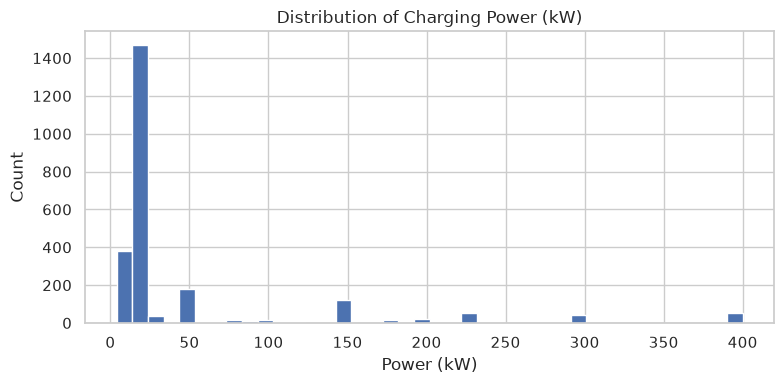

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['power_kw'],
        bins=40,
        edgecolor='white')
ax.set_xlabel('Power (kW)')
ax.set_ylabel('Count')
ax.set_title('Distribution of Charging Power (kW)')
plt.tight_layout()
plt.show()

### Task 2 — Box plot: `power_kw` by `power_type`

In [9]:
df.head()

,evse_id,station_name,street,city,postal_code,lat,lon,power_kw,power_type,amperage,voltage,plug_type,is_open_24h,renewable_energy,auth_mode
0,CH*CCI*E22078,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
1,CH*CCI*E22076,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
2,CH*CCI*E22079,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic
3,CH*CCC*E50084,MOVE - La Côte Jura,La Côte/A1 nord,Bursins,1183,46.446593,6.297621,224.0,DC,560,400,CCS Combo 2 Plug (Cable Attached),True,False,NFC RFID Classic
4,CH*CCI*E22077,SIG CERN Esplanade des Particules,SIG CERN Esplanade des Particules,Meyrin,1217,46.234320,6.055602,22.0,AC_3_PHASE,32,230,Type 2 Outlet,True,False,NFC RFID Classic


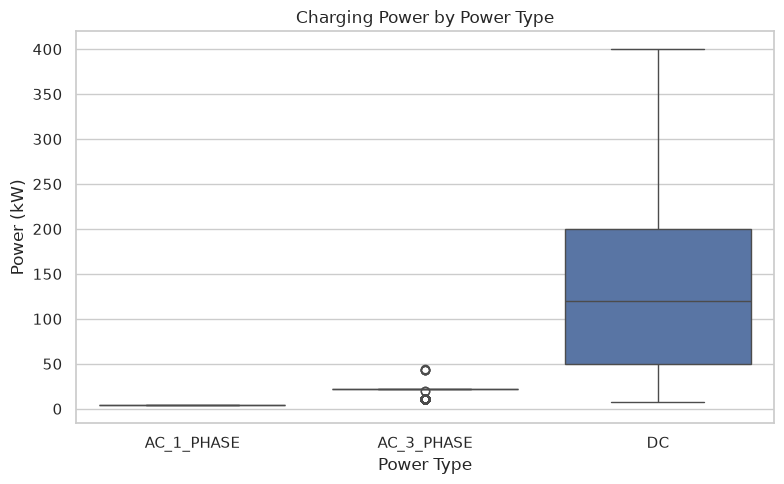

In [10]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='power_type',
    y='power_kw',
    ax=ax,
    order=['AC_1_PHASE', 'AC_3_PHASE', 'DC'])

ax.set_xlabel('Power Type')
ax.set_ylabel('Power (kW)')
ax.set_title('Charging Power by Power Type')
plt.tight_layout()
plt.show()

### Task 3 — Bar chart: top 10 cities by station count

In [ ]:
top10 = df['city'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top10.index[::-1],
        top10.values[::-1],
        color='steelblue',
        edgecolor='white')
ax.set_xlabel('Number of Charging Stations')
ax.set_title('Top 10 Cities by Number of EV Charging Stations')
plt.tight_layout()
plt.show()

### Task 4 — QQ plot of `power_kw`

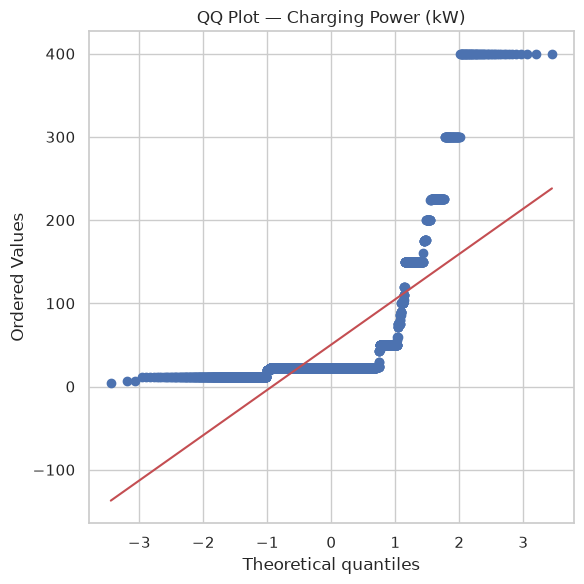

In [11]:
import scipy.stats as stats

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df['power_kw'], dist='norm', plot=ax)
ax.set_title('QQ Plot — Charging Power (kW)')
plt.tight_layout()
plt.show()

### Task 5 — Scatter plot: `voltage` vs. `amperage` coloured by `power_type`

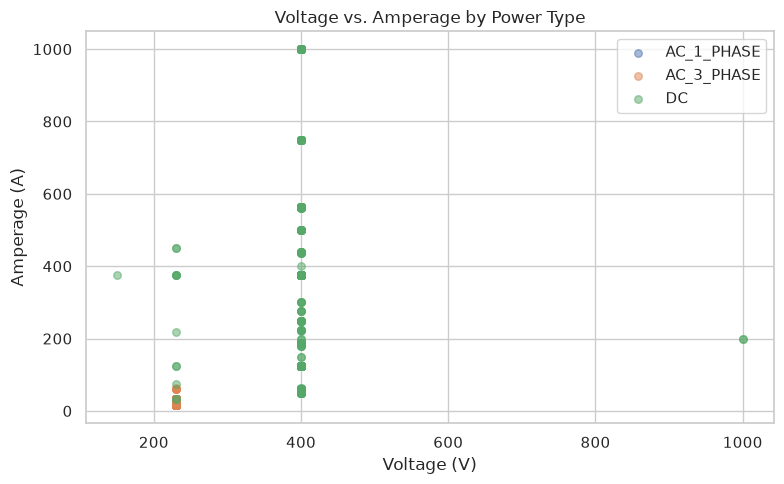

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

for ptype, grp in df.groupby('power_type'):
    ax.scatter(grp['voltage'], grp['amperage'], label=ptype, alpha=0.5, s=30)

ax.set_xlabel('Voltage (V)')
ax.set_ylabel('Amperage (A)')
ax.set_title('Voltage vs. Amperage by Power Type')
ax.legend()
plt.tight_layout()
plt.show()

### Task 6 — Scatter plot matrix

In [ ]:
# YOUR CODE HERE


### Task 7 — Hexbin plot: `voltage` vs. `amperage`

In [ ]:
# YOUR CODE HERE


### Task 8 — Correlation heatmap

In [ ]:
# YOUR CODE HERE


## Jupyter notebook --footer info--
(please always provide this at the end of each notebook)

In [ ]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('------------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('------------------------------------')